# California Housing — Análise Exploratória (EDA)

Objetivo: conhecer o dataset antes de treinar qualquer modelo.

Cada linha é um **bloco censitário** da Califórnia (censo de 1990). A variável alvo é `MedHouseVal`, o valor mediano das casas do bloco, em **centenas de milhares de dólares** (ex.: 2.5 = US\$ 250.000).

> **Como usar este notebook:** execute as células em ordem, de cima para baixo, com `Shift + Enter`. Linhas que começam com `#` são **comentários**: o Python as ignora, elas servem só para explicar o código.

In [1]:
# --- Importando bibliotecas ---

import numpy as np                # NumPy: cálculos numéricos com vetores e matrizes
import pandas as pd               # pandas: manipulação de tabelas (DataFrames)
import matplotlib.pyplot as plt   # matplotlib: criação de gráficos

from sklearn.datasets import fetch_california_housing

# Configurações de exibição:
pd.set_option("display.precision", 3)   # mostra números com 3 casas decimais
plt.rcParams["figure.dpi"] = 100        # resolução dos gráficos

## 1. Carregando os dados

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# .head() mostra as 5 primeiras linhas da tabela
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521
3,5.643,52.0,5.817,1.073,558.0,2.548,37.85,-122.25,3.413
4,3.846,52.0,6.282,1.081,565.0,2.181,37.85,-122.25,3.422


A descrição oficial explica cada coluna:

In [3]:
# housing.DESCR é um texto (string) com a documentação do dataset.
# [:1800] pega apenas os primeiros 1800 caracteres (isso se chama "fatiamento").
# print() exibe o texto na tela respeitando as quebras de linha.
print(housing.DESCR[:1800])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

| Coluna | Significado |
|---|---|
| `MedInc` | Renda mediana do bloco (dezenas de milhares de US\$) |
| `HouseAge` | Idade mediana das casas |
| `AveRooms` | Média de cômodos por domicílio |
| `AveBedrms` | Média de quartos por domicílio |
| `Population` | População do bloco |
| `AveOccup` | Média de moradores por domicílio |
| `Latitude`, `Longitude` | Localização |
| `MedHouseVal` | **Alvo**: valor mediano das casas (centenas de milhares de US\$) |

## 2. Estrutura: tamanho, tipos e valores ausentes

In [4]:
# .shape atributo que devolve (número de linhas, número de colunas).
print("Formato:", df.shape)
print()

# .info() lista cada coluna com seu tipo de dado e quantos valores não nulos ela tem.
df.info()

Formato: (20640, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
# .isna() cria uma tabela de True/False: True onde o valor está ausente (vazio).
# .sum() soma cada coluna. Como True vale 1 e False vale 0,
# o resultado é a quantidade de valores ausentes por coluna.
print("Valores ausentes por coluna:")
df.isna().sum()

Valores ausentes por coluna:


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

## 3. Estatísticas descritivas

Compare `mean`, `50%` (mediana) e `max`: quando o máximo fica muito longe da mediana, há outliers.

In [18]:
# .describe() calcula estatísticas de cada coluna numérica:
#   count = quantidade de valores   mean = média        std = desvio padrão
#   min/max = mínimo e máximo       25%/50%/75% = quartis (50% é a mediana)
# .T "transpõe" a tabela (troca linhas por colunas), o que facilita a leitura aqui.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


## 4. Distribuição de cada variável

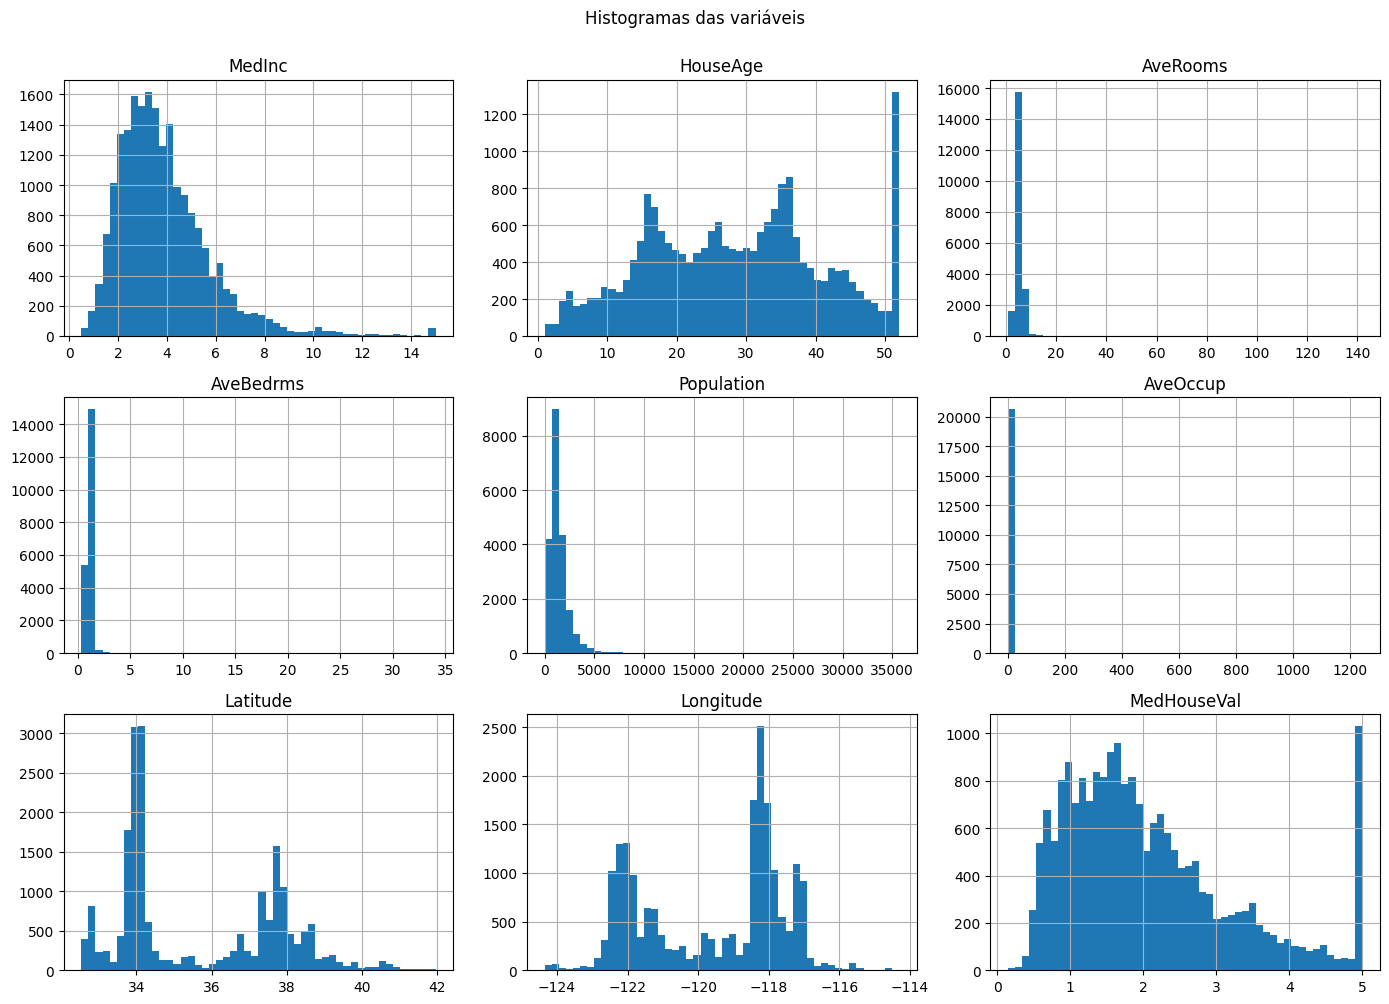

In [23]:
# .hist() desenha um histograma para cada coluna de uma vez.
# Um histograma divide os valores em faixas e mostra quantas linhas caem em cada faixa.
#   bins=50          -> número de faixas (barras)
#   figsize=(14, 10) -> tamanho da figura (largura, altura) em polegadas
df.hist(bins=50, figsize=(14, 10))

plt.suptitle("Histogramas das variáveis", y=1.0)  # título geral da figura
plt.tight_layout()   # ajusta os espaçamentos para os gráficos não se sobreporem
plt.show()           # exibe a figura

**O que observar:**
- `MedHouseVal` tem um pico em ~5.0: os valores foram **limitados (capped)** em US\$ 500 mil. O mesmo ocorre com `HouseAge` em 52.
- `AveRooms`, `AveBedrms`, `Population` e `AveOccup` têm caudas longas à direita (outliers extremos).
- As variáveis estão em escalas bem diferentes, o que importa para modelos como regressão linear e KNN.

In [26]:
# df["MedHouseVal"] seleciona uma única coluna da tabela (isso é uma "Series" no pandas).
# ">= 5.0" compara cada valor e gera True/False; .sum() conta quantos são True.
cappedMedHouseVal = (df["MedHouseVal"] >= 5.0).sum()

# ">= 52" compara cada valor e gera True/False; .sum() conta quantos são True.
cappedHouseAge = (df["HouseAge"] >= 52).sum()

# Intersecção: casas que possuem o valor limitado E a idade limitada ao mesmo tempo
cappedIntersection = ((df["MedHouseVal"] >= 5.0) & (df["HouseAge"] >= 52)).sum()

# len(df) é o número total de linhas.
# O f antes das aspas cria uma "f-string": o que está entre {} é substituído pelo valor.
# {... :.1%} formata o número como porcentagem com 1 casa decimal.
print(f"Blocos com valor limitado em 5.0: {cappedMedHouseVal} ({cappedMedHouseVal / len(df):.1%})")
print(f"Blocos com idade limitado em 52: {cappedHouseAge} ({cappedHouseAge / len(df):.1%})")
print(f"Blocos na intersecção (ambas as condições): {cappedIntersection} ({cappedIntersection / len(df):.1%})")

Blocos com valor limitado em 5.0: 992 (4.8%)
Blocos com idade limitado em 52: 1273 (6.2%)
Blocos na intersecção (ambas as condições): 180 (0.9%)


## 5. Outliers

Boxplots das variáveis com caudas longas:

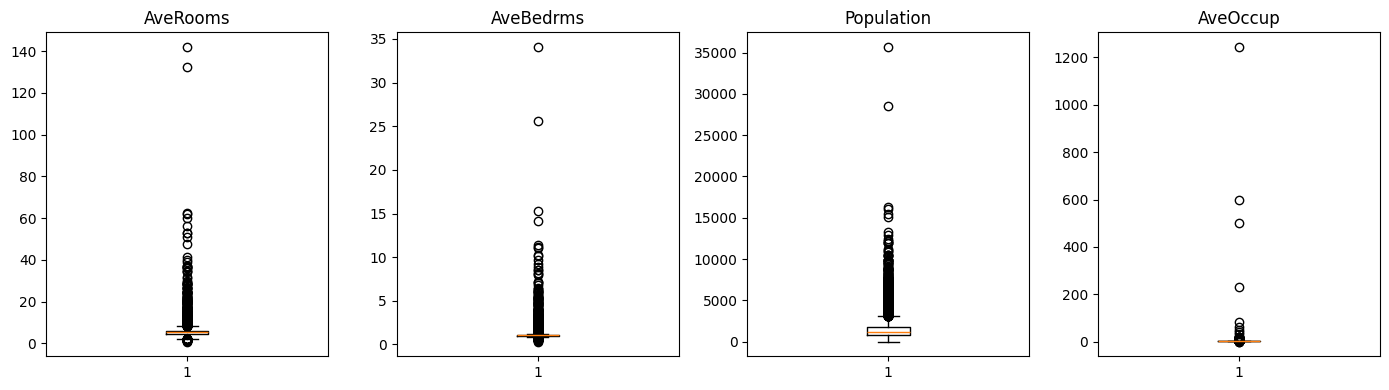

,AveRooms,AveBedrms,Population,AveOccup
0.50,5.229,1.049,1166.00,2.818
0.99,10.357,2.128,5805.83,5.395
1.00,141.909,34.067,35682.00,1243.333


In [30]:
# Uma lista em Python é escrita entre colchetes. Aqui guardamos os nomes das colunas.
cols = ["AveRooms", "AveBedrms", "Population", "AveOccup"]

# plt.subplots cria uma figura ("fig") com vários gráficos lado a lado ("axes").
# 1 linha e len(cols) = 4 colunas de gráficos.
fig, axes = plt.subplots(1, len(cols), figsize=(14, 4))

# "for" repete o bloco indentado (com recuo) para cada item.
# zip() junta as duas listas em pares: (1º gráfico, 1ª coluna), (2º gráfico, 2ª coluna)...
for ax, col in zip(axes, cols):
    ax.boxplot(df[col])   # boxplot: a caixa vai do 25% ao 75%; os pontos soltos são outliers
    ax.set_title(col)     # título de cada gráfico

plt.tight_layout()
plt.show()

# Mostra a mediana (0.5), o percentil 99 (0.99) e o máximo (1.0) dessas colunas.
# Compare o 99% com o máximo: a diferença enorme revela os valores extremos.
df[cols].quantile([0.5, 0.99, 1.0])

## 6. Correlação com o alvo

In [10]:
# .corr() calcula a correlação de Pearson entre todos os pares de colunas.
# O valor vai de -1 a 1:
#    1 -> quando uma sobe, a outra sobe junto (relação linear perfeita)
#    0 -> sem relação linear
#   -1 -> quando uma sobe, a outra desce
corr = df.corr()

# Pegamos só a coluna do alvo e ordenamos da maior para a menor correlação.
corr["MedHouseVal"].sort_values(ascending=False)

MedHouseVal    1.000
MedInc         0.688
AveRooms       0.152
HouseAge       0.106
AveOccup      -0.024
Population    -0.025
Longitude     -0.046
AveBedrms     -0.047
Latitude      -0.144
Name: MedHouseVal, dtype: float64

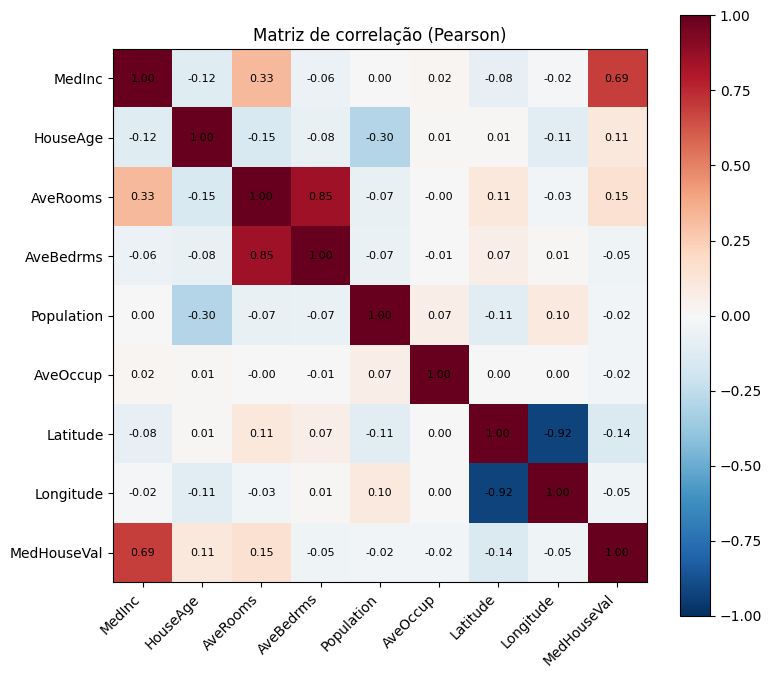

In [11]:
# Vamos desenhar a matriz de correlação como um "mapa de calor".
fig, ax = plt.subplots(figsize=(8, 7))

# imshow pinta cada célula da matriz com uma cor.
#   cmap="RdBu_r"      -> escala de cores: azul (negativo) até vermelho (positivo)
#   vmin=-1, vmax=1    -> fixa os limites da escala de cores
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)

# Coloca os nomes das colunas nos eixos. range(n) gera os números 0, 1, ..., n-1.
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)

# Dois "for" um dentro do outro percorrem todas as células (linha i, coluna j)
# e escrevem o valor da correlação no centro de cada uma.
# .iloc[i, j] acessa a célula pela posição numérica.
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im)   # barra lateral com a legenda das cores
ax.set_title("Matriz de correlação (Pearson)")
plt.tight_layout()
plt.show()

**O que observar:** `MedInc` é de longe a variável mais correlacionada com o preço (~0.69). `AveRooms` e `AveBedrms` são muito correlacionadas entre si, assim como `Latitude` e `Longitude` (negativamente).

Lembre que a correlação de Pearson só mede relações **lineares**.

## 7. Renda × Valor da casa

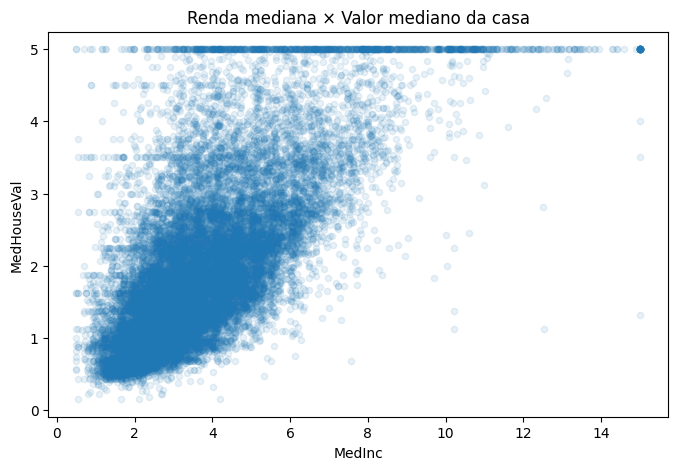

In [12]:
# Gráfico de dispersão: cada ponto é um bloco censitário.
#   x = renda, y = valor da casa
#   alpha=0.1 deixa os pontos 90% transparentes; onde há muitos pontos
#   sobrepostos a cor fica mais forte, revelando onde os dados se concentram.
df.plot.scatter(x="MedInc", y="MedHouseVal", alpha=0.1, figsize=(8, 5))
plt.title("Renda mediana × Valor mediano da casa")
plt.show()

Note a tendência crescente e a linha horizontal em 5.0 (o limite). Também aparecem linhas mais fracas em ~4.5 e ~3.5.

## 8. Geografia

Plotando longitude × latitude, o mapa da Califórnia aparece. O tamanho do ponto é a população, e a cor é o valor da casa.

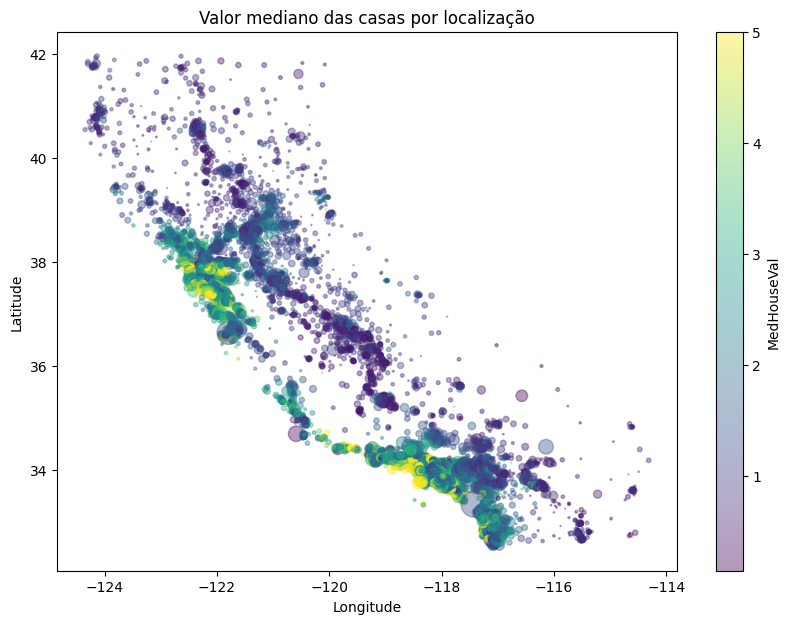

In [13]:
# Mesmo tipo de gráfico de dispersão, mas usando a localização como x e y.
ax = df.plot.scatter(
    x="Longitude", y="Latitude",
    s=df["Population"] / 100,   # s = tamanho de cada ponto (dividimos para não ficar enorme)
    c="MedHouseVal",            # c = cor de cada ponto, conforme o valor da casa
    cmap="viridis",             # escala de cores: roxo (barato) até amarelo (caro)
    alpha=0.4,
    figsize=(10, 7),
    colorbar=True,              # mostra a legenda de cores
)
ax.set_title("Valor mediano das casas por localização")
plt.show()

Os valores mais altos se concentram no litoral, perto da Baía de São Francisco e de Los Angeles. A localização é um preditor forte, mesmo com correlação linear fraca.

## 9. Atributos derivados

Combinações de colunas às vezes explicam melhor o alvo do que as colunas originais:

In [14]:
# .copy() cria uma cópia independente da tabela.
# Assim podemos adicionar colunas sem alterar o "df" original.
df_feat = df.copy()

# Criar uma coluna nova é só atribuir a um nome que ainda não existe.
# A divisão é feita linha a linha, automaticamente, para a tabela inteira.
df_feat["BedrmsPerRoom"] = df_feat["AveBedrms"] / df_feat["AveRooms"]   # proporção de quartos entre os cômodos
df_feat["RoomsPerPerson"] = df_feat["AveRooms"] / df_feat["AveOccup"]   # cômodos por morador

# Recalculamos a correlação para ver se as novas colunas se relacionam mais com o preço.
df_feat.corr()["MedHouseVal"].sort_values(ascending=False)

MedHouseVal       1.000
MedInc            0.688
RoomsPerPerson    0.209
AveRooms          0.152
HouseAge          0.106
AveOccup         -0.024
Population       -0.025
Longitude        -0.046
AveBedrms        -0.047
Latitude         -0.144
BedrmsPerRoom    -0.256
Name: MedHouseVal, dtype: float64

## 10. Resumo e próximos passos

**Achados**
- 20.640 linhas, 8 atributos numéricos e nenhum valor ausente.
- O alvo é limitado em 5.0, e `HouseAge` em 52.
- Há outliers extremos em `AveRooms`, `AveBedrms`, `Population` e `AveOccup`.
- `MedInc` é o melhor preditor linear, e a localização tem forte efeito não linear.
- Os atributos derivados `BedrmsPerRoom` e `RoomsPerPerson` correlacionam mais com o preço do que as colunas originais de cômodos.

**Próximos passos sugeridos**
1. Separar treino e teste (`train_test_split`) **antes** de qualquer outra transformação, para evitar vazamento de dados.
2. Montar um `Pipeline` com `StandardScaler` e um modelo base (`LinearRegression`).
3. Comparar com modelos não lineares (`DecisionTreeRegressor`, `RandomForestRegressor`).
4. Avaliar com RMSE e validação cruzada (`cross_val_score`).